## **Messwerte (Leerlauf)**

In [9]:
import numpy as np


f_1 = 130 #Erste Frequenz in Hz
f_1_Fehler = 1
omega_1 = f_1 * 2*np.pi
omega_1_Fehler = f_1_Fehler * 2*np.pi

N_1 = 50 #Primärwindungszahl
N_2 = np.array([85, 100, 120, 140, 170, 200, 240, 290, 350, 420, 500, 15, 40, 60, 80]) #Sekundärwindungszahl

U1_f1 = np.array([0.232, 0.232 , 0.232, 0.232, 0.232, 0.232, 0.232, 0.232, 0.232, 0.232, 0.232, 0.232, 0.232, 0.232, 0.232]) #Primärspannung bei Frequenz 1 in Volt
U1_f1_Fehler = 0.002

I1_f1 = np.array([31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0]) *(10**(-3))#Primärstrom bei Frequenz 1 in Ampere
I1_f1_Fehler = 0.2e-3

U2_f1 = np.array([0.366, 0.458, 0.550, 0.642, 0.780, 0.916, 1.101, 1.330, 1.604, 1.924, 2.28, 0.092, 0.183, 0.274, 0.320]) #Sekundärspannung bei Frequenz 1 in Volt
U2_f1_Fehler = 0.002



"""-----------------------------------------------------------------------------------------------------------------------------------"""



f_2 = 320 #Zweite Frequenz in Hz
f_2_Fehler = 1
omega_2 = f_2 * 2*np.pi
omega_2_Fehler = f_2_Fehler * 2*np.pi

U1_f2 = np.array([0.489, 0.489, 0.489, 0.489, 0.489, 0.489, 0.489, 0.489, 0.489, 0.489, 0.489, 0.489,0.489, 0.489, 0.489]) #Primärspannung bei Frequenz 2 in Volt
U1_f2_Fehler = 0.002

I1_f2 = np.array([28.2, 28.2, 28.2, 28.2, 28.2, 28.2, 28.2, 28.2, 28.2, 28.2, 28.2, 28.2, 28.2, 28.2, 28.2])*10**(-3) #Primärstrom bei Frequenz 2 in Ampere
I1_f2_Fehler = 0.2e-3

U2_f2 = np.array([0.774, 0.969, 1.163, 1.358, 1.648, 1.937, 2.30, 2.78, 3.36, 4.04, 4.80, 0.18, 0.37, 0.56, 0.74]) #Sekundärspannung bei Frequenz 2 in Volt
U2_f2_Fehler = 0.002


## **Berechnung der Induktivitäten für f_1**

In [10]:
import sympy as sp
from Skripte.Fehlerfortpflanzung import Gaußfehler
from IPython.display import display

#Berechnungen für Frequenz 1

#Berechung von L1
L1_f1 = U1_f1 / (omega_1 * I1_f1)
L1_f1_Fehler = np.zeros(len(L1_f1), dtype = float)

U1p, omega1p, I1p = sp.symbols("U_1, omega_1, I_1")
expr1 = U1p / (omega1p * I1p)
display(expr1)
Variablen_1 = np.array([U1p, omega1p, I1p])

Fehler_1 = np.array([U1_f1_Fehler, omega_1_Fehler, I1_f1_Fehler])

for i in range(len(L1_f1_Fehler)):
    L1_f1_Fehler[i] = Gaußfehler(expr1, Variablen_1, np.array([U1_f1[i], omega_1, I1_f1[i]]), Fehler_1)

#Berechnung von L12
L12_f1 = U2_f1 / (omega_1 * I1_f1)
L12_f1_Fehler = np.zeros(len(L12_f1), dtype = float)

U2p, omega1p, I1p = sp.symbols("U_2, omega_1, I_1")
expr2 = U2p / (omega1p * I1p)
display(expr2)
Variablen_2 = np.array([U2p, omega1p, I1p])

Fehler_2 = np.array([U2_f1_Fehler, omega_1_Fehler, I1_f1_Fehler])

for i in range(len(L12_f1_Fehler)):
    L12_f1_Fehler[i] = Gaußfehler(expr2, Variablen_2, np.array([U2_f1[i], omega_1, I1_f1[i]]), Fehler_2)

print(f"Induktivitäten für f_1 = {f_1}Hz:")
for i in range(len(L1_f1)):
    print(f"für N_2 = {N_2[i]} gilt: L_1 = ({L1_f1[i]} +/- {L1_f1_Fehler[i]})H und Kopplung L_12 = ({L12_f1[i]} +/- {L12_f1_Fehler[i]})H")

%store L12_f1
%store L12_f1_Fehler
%store L1_f1
%store L1_f1_Fehler

U_1/(I_1*omega_1)

U_2/(I_1*omega_1)

Induktivitäten für f_1 = 130Hz:
für N_2 = 85 gilt: L_1 = (0.009162269676754273 +/- 0.00012124393652885585)H und Kopplung L_12 = (0.014454270265914069 +/- 0.0001652189847225195)H
für N_2 = 100 gilt: L_1 = (0.009162269676754273 +/- 0.00012124393652885585)H und Kopplung L_12 = (0.01808758410324766 +/- 0.00019802720898646952)H
für N_2 = 120 gilt: L_1 = (0.009162269676754273 +/- 0.00012124393652885585)H und Kopplung L_12 = (0.02172089794058125 +/- 0.00023193408341823967)H
für N_2 = 140 gilt: L_1 = (0.009162269676754273 +/- 0.00012124393652885585)H und Kopplung L_12 = (0.02535421177791484 +/- 0.00026652062503491994)H
für N_2 = 170 gilt: L_1 = (0.009162269676754273 +/- 0.00012124393652885585)H und Kopplung L_12 = (0.03080418253391523 +/- 0.00031919068698335335)H
für N_2 = 200 gilt: L_1 = (0.009162269676754273 +/- 0.00012124393652885585)H und Kopplung L_12 = (0.03617516820649532 +/- 0.00037167616521260866)H
für N_2 = 240 gilt: L_1 = (0.009162269676754273 +/- 0.00012124393652885585)H und Kopplu

## **Berechnung der Induktivitäten für f_2**

In [11]:
#Berechnungen für Frequenz 2

#Berechung von L1
L1_f2 = U1_f2 / (omega_2 * I1_f2)
L1_f2_Fehler = np.zeros(len(L1_f2), dtype = float)

U1p, omega2p, I1p = sp.symbols("U_1, omega_2, I_1")
expr1 = U1p / (omega2p * I1p)
display(expr1)
Variablen_1 = np.array([U1p, omega2p, I1p])

Fehler_1 = np.array([U1_f2_Fehler, omega_2_Fehler, I1_f2_Fehler])

for i in range(len(L1_f2_Fehler)):
    L1_f2_Fehler[i] = Gaußfehler(expr1, Variablen_1, np.array([U1_f2[i], omega_2, I1_f2[i]]), Fehler_1)

#Berechnung von L12
L12_f2 = U2_f2 / (omega_2 * I1_f2)
L12_f2_Fehler = np.zeros(len(L12_f2), dtype = float)

U2p, omega2p, I1p = sp.symbols("U_2, omega_2, I_1")
expr2 = U2p / (omega2p * I1p)
display(expr2)
Variablen_2 = np.array([U2p, omega2p, I1p])

Fehler_2 = np.array([U2_f2_Fehler, omega_2_Fehler, I1_f2_Fehler])

for i in range(len(L12_f2_Fehler)):
    L12_f2_Fehler[i] = Gaußfehler(expr2, Variablen_2, np.array([U2_f2[i], omega_2, I1_f2[i]]), Fehler_2)

print(f"Induktivitäten für f_2 = {f_2}Hz:")
for i in range(len(L1_f2)):
    print(f"für N_2 = {N_2[i]} gilt: L_1 = ({L1_f2[i]} +/- {L1_f2_Fehler[i]})H und Kopplung L_12 = ({L12_f2[i]} +/- {L12_f2_Fehler[i]})H")

%store L12_f2
%store L12_f2_Fehler
%store L1_f2
%store L1_f2_Fehler

U_1/(I_1*omega_2)

U_2/(I_1*omega_2)

Induktivitäten für f_2 = 320Hz:
für N_2 = 85 gilt: L_1 = (0.008624420121003637 +/- 7.557710712166896e-05)H und Kopplung L_12 = (0.01365092264551496 +/- 0.00011152215216272093)H
für N_2 = 100 gilt: L_1 = (0.008624420121003637 +/- 7.557710712166896e-05)H und Kopplung L_12 = (0.017090108583338495 +/- 0.00013706750111643396)H
für N_2 = 120 gilt: L_1 = (0.008624420121003637 +/- 7.557710712166896e-05)H und Kopplung L_12 = (0.020511657670198837 +/- 0.000162834970847043)H
für N_2 = 140 gilt: L_1 = (0.008624420121003637 +/- 7.557710712166896e-05)H und Kopplung L_12 = (0.023950843608022375 +/- 0.00018894454563701796)H
für N_2 = 170 gilt: L_1 = (0.008624420121003637 +/- 7.557710712166896e-05)H und Kopplung L_12 = (0.02906553038734968 +/- 0.0002280073905165686)H
für N_2 = 200 gilt: L_1 = (0.008624420121003637 +/- 7.557710712166896e-05)H und Kopplung L_12 = (0.03416258031571379 +/- 0.0002671046573315396)H
für N_2 = 240 gilt: L_1 = (0.008624420121003637 +/- 7.557710712166896e-05)H und Kopplung L_12 

## **Kopplungsgrad aus linearer Regression**

U_2/U_1

Kopplungsgrad für f_1 = 130: kappa = 0.9665826098267982 +/- 0.003619974357728559
Kopplungsgrad für f_2 = 320: kappa = 0.9731815995680316 +/- 0.0017094059908748115


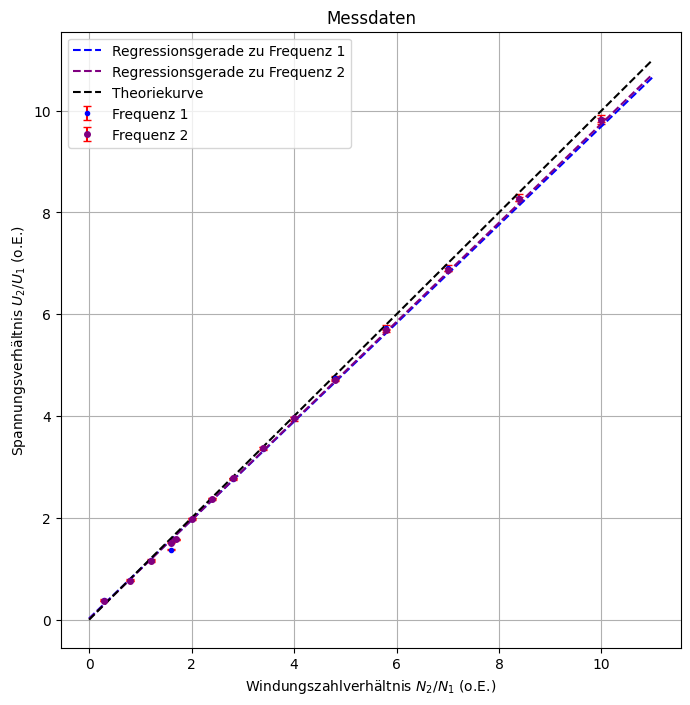

In [12]:
import scipy.optimize
import matplotlib.pyplot as plt

N_Ratio = N_2 / N_1

U1p, U2p = sp.symbols("U_1, U_2")
expr3 = U2p / U1p
display(expr3)
Variablen = np.array([U1p, U2p])

#Frequenz 1
U_Ratio_f1 = U2_f1 / U1_f1
U_Ratio_f1_Fehler = np.zeros(len(U_Ratio_f1), dtype = float)

for i in range(len(U_Ratio_f1_Fehler)):
    U_Ratio_f1_Fehler[i] = Gaußfehler(expr3, Variablen, np.array([U1_f1[i], U2_f1[i]]), np.array([U1_f1_Fehler, U2_f1_Fehler]))

#Frequenz 2
U_Ratio_f2 = U2_f2 / U1_f2
U_Ratio_f2_Fehler = np.zeros(len(U_Ratio_f2), dtype = float)

for i in range(len(U_Ratio_f2_Fehler)):
    U_Ratio_f2_Fehler[i] = Gaußfehler(expr3, Variablen, np.array([U1_f2[i], U2_f2[i]]), np.array([U1_f2_Fehler, U2_f2_Fehler]))

#Lineare Regression

def f(x,k,c):
    return k*x + c #Fit Funktion

coefficients1, pcov1 = scipy.optimize.curve_fit(f, N_Ratio, U_Ratio_f1, sigma= U_Ratio_f1_Fehler, absolute_sigma= True)
kappa_1 = coefficients1[0]
kappa_1_Fehler = np.sqrt(pcov1[0,0])
c_1 = coefficients1[1]

print(f"Kopplungsgrad für f_1 = {f_1}: kappa = {kappa_1} +/- {kappa_1_Fehler}")

coefficients2, pcov2 = scipy.optimize.curve_fit(f, N_Ratio, U_Ratio_f2, sigma= U_Ratio_f2_Fehler, absolute_sigma= True)
kappa_2 = coefficients2[0]
kappa_2_Fehler = np.sqrt(pcov2[0,0])
c_2 = coefficients2[1]

print(f"Kopplungsgrad für f_2 = {f_2}: kappa = {kappa_2} +/- {kappa_2_Fehler}")

#Plot
fig, ax1 = plt.subplots(1, 1, figsize=(8, 8))

ax1.errorbar(N_Ratio, U_Ratio_f1, yerr=U_Ratio_f1_Fehler, fmt="o", label="Frequenz 1", color="blue", markersize=3, capsize=3, ecolor="r")
ax1.errorbar(N_Ratio, U_Ratio_f2, yerr=U_Ratio_f2_Fehler, fmt="o", label="Frequenz 2", color="purple", markersize=4, capsize=3, ecolor="r")

xwerte = np.linspace(0, np.max(N_Ratio)*1.1, 500)
ax1.plot(xwerte, kappa_1*xwerte + c_1, color = "blue", linestyle = "--", label = "Regressionsgerade zu Frequenz 1")
ax1.plot(xwerte, kappa_2*xwerte + c_2, color = "purple", linestyle = "--", label = "Regressionsgerade zu Frequenz 2")

ax1.plot(xwerte, xwerte, color = "black", linestyle = "--", label = "Theoriekurve")

ax1.set_xlabel(r"Windungszahlverhältnis $N_2/N_1$ (o.E.)")
ax1.set_ylabel(r"Spannungsverhältnis $U_2/U_1$ (o.E.)")
ax1.grid(True)
ax1.set_title("Messdaten")
ax1.legend()
